# SVM Baseline — Transliteration Heavy Train → Three Test Conditions

**Project:** Robustness of SLM-Based Sinhala Hate Speech Detection Under Realistic Text Noise

## Experiment scope

This notebook trains **one SVM model only**:

> **Training:** Transliteration **Heavy** training dataset

The trained model is then evaluated **separately** on three test conditions:

1. **Transliteration Heavy test**
2. **CodeMix Heavy test**
3. **Clean SOLD test**

The clean SOLD dataset does **not** have Light/Heavy versions, so the clean evaluation uses `clean_sold_test.jsonl`.

### Important scope decision

This notebook does **not** train a Light SVM, does **not** train a Heavy SVM separately, and does **not** perform Light↔Heavy cross-severity testing.

The purpose is to measure how a classifier trained specifically on **heavy transliteration** transfers to:
- the same heavy transliteration condition,
- heavy code-mixing, and
- clean SOLD text.

The SVM methodology itself is unchanged:
- character-level TF-IDF,
- `char_wb` analyzer,
- 1–5 character n-grams,
- TF-IDF inside the cross-validation pipeline,
- class-balanced SVM,
- GridSearchCV over Linear/RBF kernels and C values,
- 5-fold stratified CV,
- Macro-F1 as the model-selection metric.


## 2. Imports and Environment Setup

The notebook uses scikit-learn for the TF-IDF + SVM pipeline, cross-validation, and evaluation metrics.


In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path
from datetime import datetime

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    classification_report,
    f1_score,
    precision_recall_fscore_support,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Imports OK")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


Imports OK
NumPy: 2.0.2
Pandas: 2.2.3


## 3. Configuration and Dataset Paths

Expected dataset layout:

```text
outputs/
├── train/
│   ├── transliteration_heavy.jsonl
│   └── ... other training files may exist but are NOT used here
└── test/
    ├── transliteration_heavy.jsonl
    ├── codemix_heavy.jsonl
    └── clean_sold_test.jsonl
```

Only the four files explicitly listed below are loaded.

**No clean SOLD training data is used in this experiment.**


In [2]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [3]:
# Edit these two paths if your Google Drive structure is different.
OUTPUTS_ROOT = "/content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs"
OUT_DIR = "/content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_transliteration_heavy_train_all_tests"

Path(OUT_DIR).mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------
# Experiment definition
# ------------------------------------------------------------------
TRAIN_CONDITION = "transliteration_heavy"

TRAIN_FILE = f"{OUTPUTS_ROOT}/train/transliteration_heavy.jsonl"

TEST_FILES = {
    "transliteration_heavy": f"{OUTPUTS_ROOT}/test/transliteration_heavy.jsonl",
    "codemix_heavy": f"{OUTPUTS_ROOT}/test/codemix_heavy.jsonl",
    "clean_sold": f"{OUTPUTS_ROOT}/test/clean_sold_test.jsonl",
}

# Column names
TRAIN_TEXT_COL = "noisy_text"
TEST_TEXT_COL = "noisy_text"
LABEL_COL = "label"

LABEL_NAMES = ["not_offensive", "offensive"]

print("OUTPUTS_ROOT :", OUTPUTS_ROOT)
print("OUT_DIR      :", OUT_DIR)
print("TRAIN_FILE   :", TRAIN_FILE)
print()
for condition, path in TEST_FILES.items():
    print(f"{condition:24s} -> {path}")


OUTPUTS_ROOT : /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs
OUT_DIR      : /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_transliteration_heavy_train_all_tests
TRAIN_FILE   : /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/train/transliteration_heavy.jsonl

transliteration_heavy    -> /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/transliteration_heavy.jsonl
codemix_heavy            -> /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/codemix_heavy.jsonl
clean_sold               -> /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/clean_sold_test.jsonl


## 4. Verify the Required Files

Before loading anything, verify that all required files exist.

This prevents accidentally running the experiment with a missing or incorrectly named dataset.


In [4]:
required_paths = {
    "transliteration_heavy_train": TRAIN_FILE,
    **TEST_FILES,
}

missing = [name for name, path in required_paths.items() if not Path(path).is_file()]

if missing:
    raise FileNotFoundError(
        "The following required files were not found:\n"
        + "\n".join(f"  - {name}: {required_paths[name]}" for name in missing)
    )

print("✓ All required files were found.")
for name, path in required_paths.items():
    print(f"  ✓ {name}: {path}")


✓ All required files were found.
  ✓ transliteration_heavy_train: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/train/transliteration_heavy.jsonl
  ✓ transliteration_heavy: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/transliteration_heavy.jsonl
  ✓ codemix_heavy: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/codemix_heavy.jsonl
  ✓ clean_sold: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/clean_sold_test.jsonl


## 5. Dataset Loading

JSONL files are loaded into pandas DataFrames.

The training set is **only** `transliteration_heavy.jsonl`.

The three test sets are loaded independently and are never used during SVM hyperparameter selection.


In [5]:
def load_jsonl(path: str) -> pd.DataFrame:
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line_number, line in enumerate(f, start=1):
            line = line.strip()
            if not line:
                continue
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError as exc:
                raise ValueError(
                    f"Invalid JSON in {path}, line {line_number}: {exc}"
                ) from exc

    if not rows:
        raise ValueError(f"Dataset is empty: {path}")

    return pd.DataFrame(rows)


train_df = load_jsonl(TRAIN_FILE)
test_data = {
    condition: load_jsonl(path)
    for condition, path in TEST_FILES.items()
}

print(f"Transliteration Heavy TRAIN : {len(train_df):,} rows")
for condition, df in test_data.items():
    print(f"{condition:28s}: {len(df):,} rows")


Transliteration Heavy TRAIN : 7,500 rows
transliteration_heavy       : 2,500 rows
codemix_heavy               : 2,500 rows
clean_sold                  : 2,500 rows


## 6. Dataset Canonicalization and Validation

The training and test datasets may use different text-column names.

For this experiment:
- Transliteration/CodeMix use `noisy_text`.
- Clean SOLD may use `text`.

The helper below selects the appropriate text field while keeping the common label representation:

- `0 = not_offensive`
- `1 = offensive`

No rows are removed merely because duplicate text exists; duplicates are reported for inspection.


In [6]:
def choose_text_column(df: pd.DataFrame, condition: str) -> str:
    if condition == "clean_sold":
        candidates = ["text", "noisy_text"]
    else:
        candidates = ["noisy_text", "text"]

    for col in candidates:
        if col in df.columns:
            return col

    raise KeyError(
        f"No supported text column found for {condition}. "
        f"Available columns: {list(df.columns)}"
    )


def canonicalize(df: pd.DataFrame, condition: str, split: str) -> pd.DataFrame:
    text_col = choose_text_column(df, condition)

    required = [text_col, LABEL_COL]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(
            f"{condition}/{split} is missing required columns: {missing}"
        )

    out = df.copy()

    out["text"] = out[text_col].astype(str)
    out[LABEL_COL] = out[LABEL_COL].astype(int)

    if out["text"].str.strip().eq("").any():
        raise ValueError(f"{condition}/{split} contains empty text values.")

    labels = sorted(out[LABEL_COL].unique().tolist())
    if labels != [0, 1]:
        raise ValueError(
            f"{condition}/{split} must contain binary labels 0 and 1; found {labels}"
        )

    out = out.reset_index(drop=True)
    out["condition"] = condition
    out["split"] = split

    return out


train_df = canonicalize(train_df, "transliteration_heavy", "train")

canonical_tests = {}
for condition, df in test_data.items():
    canonical_tests[condition] = canonicalize(df, condition, "test")

print("✓ Datasets canonicalized.")


✓ Datasets canonicalized.


In [7]:
def validate_dataset(df: pd.DataFrame, name: str) -> None:
    print("=" * 70)
    print(name)
    print("=" * 70)

    print(f"Samples          : {len(df):,}")
    print(f"Columns          : {list(df.columns)}")

    missing = df[["text", LABEL_COL]].isnull().sum()
    print("\nMissing values:")
    print(missing.to_string())

    counts = df[LABEL_COL].value_counts().sort_index()
    props = df[LABEL_COL].value_counts(normalize=True).sort_index()

    print("\nClass distribution:")
    print(
        pd.DataFrame({
            "count": counts,
            "proportion": props.round(4),
        }).rename(index={0: "not_offensive", 1: "offensive"}).to_string()
    )

    print(f"\nDuplicate texts : {df['text'].duplicated().sum():,}")
    print()


validate_dataset(train_df, "TRANSLITERATION HEAVY — TRAIN")

for condition, df in canonical_tests.items():
    validate_dataset(
        df,
        f"{condition.upper()} — TEST"
    )


TRANSLITERATION HEAVY — TRAIN
Samples          : 7,500
Columns          : ['source_id', 'split', 'condition', 'severity', 'original_text', 'noisy_text', 'label', 'realised_noise_rate', 'generator_version', 'text']

Missing values:
text     0
label    0

Class distribution:
               count  proportion
label                           
not_offensive   4324      0.5765
offensive       3176      0.4235

Duplicate texts : 0

TRANSLITERATION_HEAVY — TEST
Samples          : 2,500
Columns          : ['source_id', 'split', 'condition', 'severity', 'original_text', 'noisy_text', 'label', 'realised_noise_rate', 'generator_version', 'text']

Missing values:
text     0
label    0

Class distribution:
               count  proportion
label                           
not_offensive   1485       0.594
offensive       1015       0.406

Duplicate texts : 0

CODEMIX_HEAVY — TEST
Samples          : 2,500
Columns          : ['source_id', 'split', 'condition', 'severity', 'original_text', 'noisy_text', '

## 7. Train/Test Source-ID Leakage Check

The underlying `source_id` is checked when it is available.

The training set contains the heavy transliteration versions of the source posts, while the three test sets may contain transformed versions of those same original posts.

Therefore, **zero source-ID overlap is required** between the heavy-transliteration training set and each test set before making a generalisation claim.

If the datasets intentionally contain the same source IDs across train/test, this check will stop the experiment rather than silently allowing possible leakage.

If `source_id` is absent from any dataset, the notebook reports that ID-based checking cannot be performed for that dataset; it does not invent an ID.


In [8]:
def check_source_id_overlap(train_df: pd.DataFrame, test_df: pd.DataFrame, test_name: str) -> None:
    if "source_id" not in train_df.columns or "source_id" not in test_df.columns:
        print(
            f"WARNING: source_id unavailable for {test_name}; "
            "source-ID leakage cannot be checked for this condition."
        )
        return

    train_ids = set(train_df["source_id"].astype(str))
    test_ids = set(test_df["source_id"].astype(str))
    overlap = train_ids & test_ids

    print(
        f"Heavy Transliteration TRAIN ∩ {test_name} TEST : "
        f"{len(overlap):,} overlapping source IDs"
    )

    if overlap:
        examples = sorted(overlap)[:10]
        raise AssertionError(
            f"Source-ID leakage detected between heavy transliteration train "
            f"and {test_name} test. Example IDs: {examples}"
        )


print("=" * 70)
print("TRAIN/TEST SOURCE-ID LEAKAGE CHECK")
print("=" * 70)

for condition, df in canonical_tests.items():
    check_source_id_overlap(train_df, df, condition.upper())

print("\n✓ Source-ID leakage checks completed.")


TRAIN/TEST SOURCE-ID LEAKAGE CHECK
Heavy Transliteration TRAIN ∩ TRANSLITERATION_HEAVY TEST : 0 overlapping source IDs
Heavy Transliteration TRAIN ∩ CODEMIX_HEAVY TEST : 0 overlapping source IDs

✓ Source-ID leakage checks completed.


## 8. Class Distribution Analysis

The SVM uses `class_weight="balanced"` so that the class imbalance in the training data is accounted for during fitting.

Macro-F1 is the primary evaluation metric because it gives equal importance to the two classes.


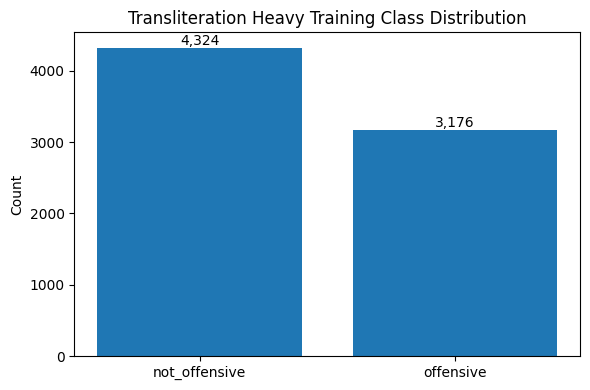

In [9]:
counts = train_df[LABEL_COL].value_counts().sort_index()

plt.figure(figsize=(6, 4))
bars = plt.bar(
    ["not_offensive", "offensive"],
    [counts.get(0, 0), counts.get(1, 0)],
)
plt.ylabel("Count")
plt.title("Transliteration Heavy Training Class Distribution")

for bar, value in zip(bars, [counts.get(0, 0), counts.get(1, 0)]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. SVM Feature Representation

**Primary representation: character-level TF-IDF.**

| Parameter | Value |
|---|---|
| `analyzer` | `char_wb` |
| `ngram_range` | `(1, 5)` |
| `min_df` | `2` |
| `sublinear_tf` | `True` |

The TF-IDF vectorizer is kept **inside the scikit-learn Pipeline**.

This is important: during GridSearchCV, each fold fits TF-IDF only on that fold's training portion. The held-out fold is never used to build the vocabulary or calculate IDF statistics.

Therefore, the feature extraction step does not leak information from the validation fold or test sets.


In [10]:
def build_svm_pipeline() -> Pipeline:
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(1, 5),
            min_df=2,
            sublinear_tf=True,
        )),
        ("svm", SVC(
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ])


print(build_svm_pipeline())


Pipeline(steps=[('tfidf',
                 TfidfVectorizer(analyzer='char_wb', min_df=2,
                                 ngram_range=(1, 5), sublinear_tf=True)),
                ('svm', SVC(class_weight='balanced', random_state=42))])


## 10. Hyperparameter Tuning

The SVM kernel and regularisation parameter are selected using 5-fold stratified cross-validation.

### Search grid

- `kernel`: `linear`, `rbf`
- `C`: `0.1`, `1`, `3`, `10`
- scoring: **Macro-F1**
- CV: **5-fold StratifiedKFold**

This produces:

**2 kernels × 4 C values × 5 folds = 40 SVM fits.**

The test sets are completely excluded from this process.


In [11]:
SVM_PARAM_GRID = {
    "svm__kernel": ["linear", "rbf"],
    "svm__C": [0.1, 1, 3, 10],
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

print("SVM parameter grid:")
print(SVM_PARAM_GRID)


SVM parameter grid:
{'svm__kernel': ['linear', 'rbf'], 'svm__C': [0.1, 1, 3, 10]}


## 11. Train the Single Heavy-Transliteration SVM

Only `transliteration_heavy.jsonl` is used for training.

There is **no Light training model** in this notebook.

The fitted pipeline returned by GridSearchCV contains both:
1. the TF-IDF vectorizer, and
2. the selected SVM.


In [12]:
X_train = train_df["text"].values
y_train = train_df[LABEL_COL].values

print("=" * 70)
print("TRAINING: TRANSLITERATION HEAVY")
print("=" * 70)
print(f"Training samples: {len(y_train):,}")
print(
    f"not_offensive={(y_train == 0).sum():,} | "
    f"offensive={(y_train == 1).sum():,}"
)

svm_pipeline = build_svm_pipeline()

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=SVM_PARAM_GRID,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=False,
)

grid_search.fit(X_train, y_train)

best_pipeline = grid_search.best_estimator_
best_params = grid_search.best_params_
best_cv_macro_f1 = grid_search.best_score_

print("\nBest parameters:", best_params)
print(f"Best CV Macro-F1: {best_cv_macro_f1:.4f}")


TRAINING: TRANSLITERATION HEAVY
Training samples: 7,500
not_offensive=4,324 | offensive=3,176
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best parameters: {'svm__C': 10, 'svm__kernel': 'rbf'}
Best CV Macro-F1: 0.7944


## 12. Evaluate the Same Trained Model on Three Test Conditions

The **same fitted heavy-transliteration SVM** is used for all three evaluations.

No retraining takes place between test conditions.

| Training | Test | Purpose |
|---|---|---|
| Transliteration Heavy | Transliteration Heavy | Same-condition performance |
| Transliteration Heavy | CodeMix Heavy | Cross-noise generalisation |
| Transliteration Heavy | Clean SOLD | Generalisation to clean text |

This is the requested three-way evaluation. There is no Light/Heavy cross-severity analysis.


In [13]:
TEST_ORDER = [
    "transliteration_heavy",
    "codemix_heavy",
    "clean_sold",
]


def evaluate_model(
    pipeline: Pipeline,
    test_df: pd.DataFrame,
    test_condition: str,
) -> tuple[dict, np.ndarray, pd.DataFrame]:

    X_test = test_df["text"].values
    y_true = test_df[LABEL_COL].values

    y_pred = pipeline.predict(X_test)
    decision_scores = pipeline.decision_function(X_test)

    acc = accuracy_score(y_true, y_pred)
    balanced_acc = balanced_accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    precision, recall, f1_per_class, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1],
        zero_division=0,
    )

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    # Baselines are calculated from TRAINING labels only.
    majority_class = int(pd.Series(y_train).mode().iloc[0])
    minority_class = 1 - majority_class

    majority_pred = np.full(len(y_true), majority_class, dtype=int)
    minority_pred = np.full(len(y_true), minority_class, dtype=int)

    majority_macro_f1 = f1_score(
        y_true, majority_pred, average="macro", zero_division=0
    )
    minority_macro_f1 = f1_score(
        y_true, minority_pred, average="macro", zero_division=0
    )

    predictions = test_df.copy()
    predictions["actual_label"] = y_true
    predictions["predicted_label"] = y_pred
    predictions["correct"] = y_pred == y_true
    predictions["decision_score"] = decision_scores

    result = {
        "training_condition": TRAIN_CONDITION,
        "testing_condition": test_condition,
        "test_size": len(y_true),
        "accuracy": acc,
        "balanced_accuracy": balanced_acc,
        "macro_f1": macro_f1,
        "cv_macro_f1": best_cv_macro_f1,
        "weighted_f1": weighted_f1,
        "precision_not_offensive": precision[0],
        "recall_not_offensive": recall[0],
        "f1_not_offensive": f1_per_class[0],
        "precision_offensive": precision[1],
        "recall_offensive": recall[1],
        "f1_offensive": f1_per_class[1],
        "support_not_offensive": int(support[0]),
        "support_offensive": int(support[1]),
        "majority_class_from_train": majority_class,
        "minority_class_from_train": minority_class,
        "majority_baseline_macro_f1": majority_macro_f1,
        "minority_baseline_macro_f1": minority_macro_f1,
        "beats_majority_baseline": macro_f1 > majority_macro_f1,
        "beats_minority_baseline": macro_f1 > minority_macro_f1,
        "best_cv_macro_f1": best_cv_macro_f1,
        "best_params": str(best_params),
    }

    print("\n" + "=" * 70)
    print(
        f"TRAIN: TRANSLITERATION HEAVY  →  TEST: {test_condition.upper()}"
    )
    print("=" * 70)
    print(f"Accuracy        : {acc:.4f}")
    print(f"Balanced Accuracy : {balanced_acc:.4f}")
    print(f"CV Macro-F1     : {best_cv_macro_f1:.4f}")
    print(f"Macro-F1        : {macro_f1:.4f}  ← primary metric")
    print(f"Weighted-F1     : {weighted_f1:.4f}")
    print()
    print(
        classification_report(
            y_true,
            y_pred,
            target_names=LABEL_NAMES,
            digits=4,
            zero_division=0,
        )
    )
    print(f">>> OFFENSIVE-CLASS RECALL = {recall[1]:.4f} <<<")
    print()
    print(
        f"Majority baseline macro-F1 : {majority_macro_f1:.4f}"
    )
    print(
        f"Minority baseline macro-F1 : {minority_macro_f1:.4f}"
    )

    return result, cm, predictions


In [14]:
all_results = []
all_cms = {}
all_preds = {}

for condition in TEST_ORDER:
    result, cm, preds = evaluate_model(
        best_pipeline,
        canonical_tests[condition],
        condition,
    )

    all_results.append(result)
    all_cms[condition] = cm
    all_preds[condition] = preds

results_df = pd.DataFrame(all_results)

print("\n✓ All three test conditions completed.")



TRAIN: TRANSLITERATION HEAVY  →  TEST: TRANSLITERATION_HEAVY
Accuracy        : 0.8080
Balanced Accuracy : 0.7874
CV Macro-F1     : 0.7944
Macro-F1        : 0.7944  ← primary metric
Weighted-F1     : 0.8043

               precision    recall  f1-score   support

not_offensive     0.8029    0.8970    0.8473      1485
    offensive     0.8181    0.6778    0.7414      1015

     accuracy                         0.8080      2500
    macro avg     0.8105    0.7874    0.7944      2500
 weighted avg     0.8091    0.8080    0.8043      2500

>>> OFFENSIVE-CLASS RECALL = 0.6778 <<<

Majority baseline macro-F1 : 0.3726
Minority baseline macro-F1 : 0.2888

TRAIN: TRANSLITERATION HEAVY  →  TEST: CODEMIX_HEAVY
Accuracy        : 0.5936
Balanced Accuracy : 0.5004
CV Macro-F1     : 0.7944
Macro-F1        : 0.3770  ← primary metric
Weighted-F1     : 0.4461

               precision    recall  f1-score   support

not_offensive     0.5942    0.9960    0.7443      1485
    offensive     0.4545    0.0049 

## 13. Results Summary

The three rows correspond to the three requested test conditions.

The model is the same in every row: **one SVM trained on Transliteration Heavy**.


In [15]:
summary_cols = [
    "training_condition",
    "testing_condition",
    "test_size",
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "cv_macro_f1",
    "weighted_f1",
    "recall_offensive",
    "recall_not_offensive",
]

print(
    results_df[summary_cols].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)


   training_condition     testing_condition  test_size  accuracy  balanced_accuracy  macro_f1  cv_macro_f1  weighted_f1  recall_offensive  recall_not_offensive
transliteration_heavy transliteration_heavy       2500    0.8080             0.7874    0.7944       0.7944       0.8043            0.6778                0.8970
transliteration_heavy         codemix_heavy       2500    0.5936             0.5004    0.3770       0.7944       0.4461            0.0049                0.9960
transliteration_heavy            clean_sold       2500    0.5952             0.5023    0.3804       0.7944       0.4490            0.0079                0.9966


## 14. Baseline Comparison

The majority and minority baselines are calculated from the **training labels only**.

No test labels are used to decide which class is the majority class.


In [16]:
print(
    f"{'Test condition':28s} "
    f"{'Majority':>12s} "
    f"{'Minority':>12s} "
    f"{'SVM Macro-F1':>14s}"
)
print("-" * 72)

for _, r in results_df.iterrows():
    print(
        f"{r['testing_condition']:28s} "
        f"{r['majority_baseline_macro_f1']:12.4f} "
        f"{r['minority_baseline_macro_f1']:12.4f} "
        f"{r['macro_f1']:14.4f}"
    )


Test condition                   Majority     Minority   SVM Macro-F1
------------------------------------------------------------------------
transliteration_heavy              0.3726       0.2888         0.7944
codemix_heavy                      0.3726       0.2888         0.3770
clean_sold                         0.3726       0.2888         0.3804


## 15. Confusion Matrices

One confusion matrix is produced for each test condition.

Rows = actual labels  
Columns = predicted labels


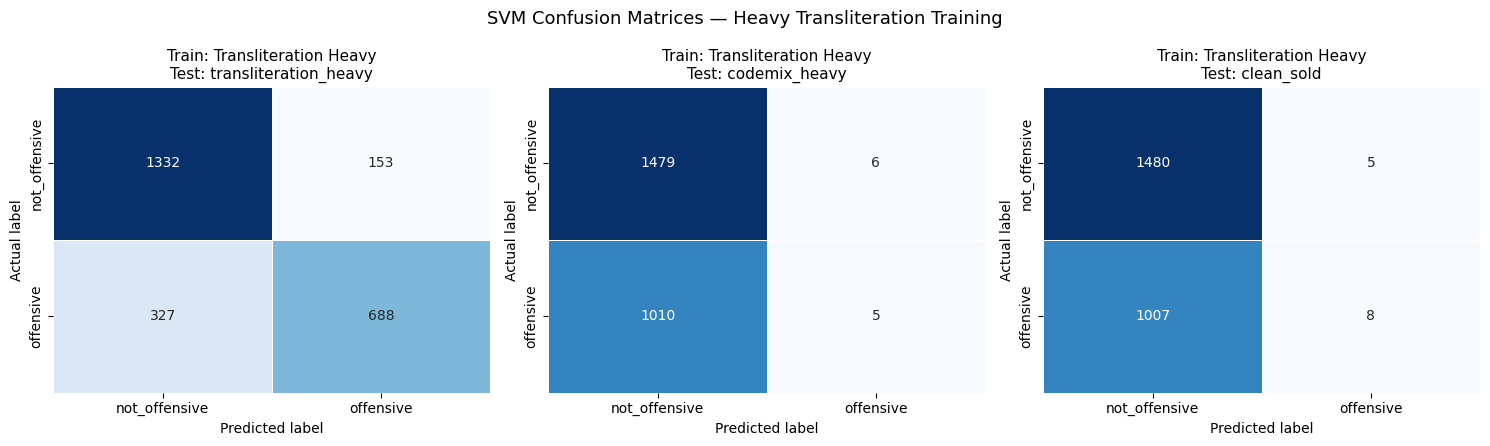

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, condition in zip(axes, TEST_ORDER):
    cm = all_cms[condition]

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=LABEL_NAMES,
        yticklabels=LABEL_NAMES,
        ax=ax,
        cbar=False,
        linewidths=0.5,
    )

    ax.set_title(
        f"Train: Transliteration Heavy\nTest: {condition}",
        fontsize=11,
    )
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.suptitle(
    "SVM Confusion Matrices — Heavy Transliteration Training",
    fontsize=13,
)
plt.tight_layout()
plt.savefig(
    f"{OUT_DIR}/confusion_matrices.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()


## 16. Performance Comparison Across Test Conditions

This plot compares Macro-F1 and Offensive Recall across the three test conditions.

There is **no Light/Heavy degradation calculation** in this notebook because only the Heavy training condition and the requested Heavy test variants are being evaluated.


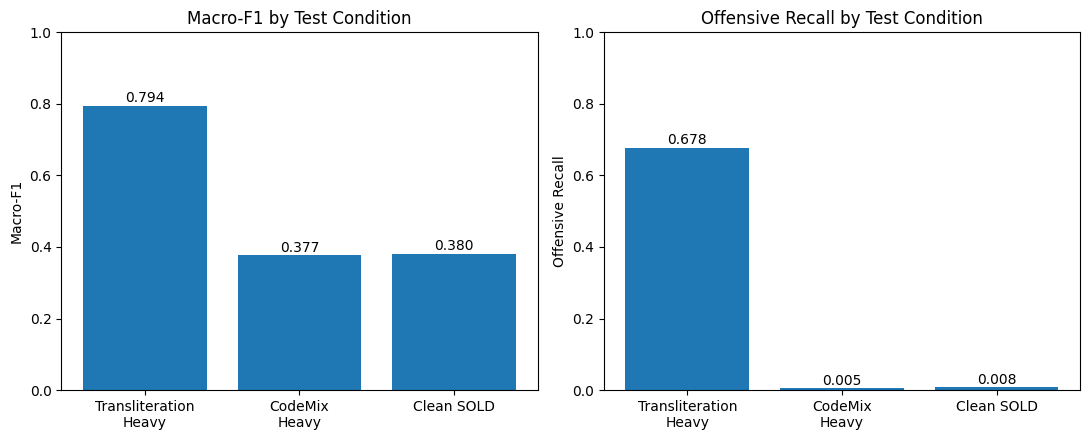

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

labels = [
    "Transliteration\nHeavy",
    "CodeMix\nHeavy",
    "Clean SOLD",
]

x = np.arange(len(TEST_ORDER))

axes[0].bar(x, results_df["macro_f1"])
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Macro-F1")
axes[0].set_title("Macro-F1 by Test Condition")

for i, value in enumerate(results_df["macro_f1"]):
    axes[0].text(i, value + 0.01, f"{value:.3f}", ha="center")

axes[1].bar(x, results_df["recall_offensive"])
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Offensive Recall")
axes[1].set_title("Offensive Recall by Test Condition")

for i, value in enumerate(results_df["recall_offensive"]):
    axes[1].text(i, value + 0.01, f"{value:.3f}", ha="center")

plt.tight_layout()
plt.savefig(
    f"{OUT_DIR}/performance_comparison.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()


## 17. Offensive-Class Analysis

Offensive recall is highlighted because missing an offensive example is particularly relevant for a hate/offensive speech detection system.


In [19]:
print(
    f"{'Test':28s} "
    f"{'Off. Precision':>15s} "
    f"{'Off. Recall':>12s} "
    f"{'Off. F1':>10s} "
    f"{'Not-Off. Recall':>16s}"
)
print("-" * 88)

for _, r in results_df.iterrows():
    print(
        f"{r['testing_condition']:28s} "
        f"{r['precision_offensive']:15.4f} "
        f"{r['recall_offensive']:12.4f} "
        f"{r['f1_offensive']:10.4f} "
        f"{r['recall_not_offensive']:16.4f}"
    )


Test                          Off. Precision  Off. Recall    Off. F1  Not-Off. Recall
----------------------------------------------------------------------------------------
transliteration_heavy                 0.8181       0.6778     0.7414           0.8970
codemix_heavy                         0.4545       0.0049     0.0097           0.9960
clean_sold                            0.6154       0.0079     0.0156           0.9966


## 18. Error Analysis

False negatives are offensive posts predicted as not-offensive.

False positives are not-offensive posts predicted as offensive.

Examples closest to the SVM decision boundary are displayed first.


In [20]:
def show_errors(preds_df: pd.DataFrame, test_condition: str, n: int = 10) -> None:
    print("\n" + "=" * 70)
    print(f"ERROR ANALYSIS — Test: {test_condition.upper()}")
    print("=" * 70)

    fn = preds_df[
        (preds_df["actual_label"] == 1)
        & (preds_df["predicted_label"] == 0)
    ].copy()

    fn["abs_decision_score"] = fn["decision_score"].abs()
    fn = fn.sort_values("abs_decision_score", ascending=True)

    print(
        f"\nFALSE NEGATIVES — {len(fn):,} total; "
        f"showing {min(n, len(fn))}:"
    )

    for _, row in fn.head(n).iterrows():
        print(f"  text: {str(row['text'])[:150]}")
        print(f"  decision_score: {row['decision_score']:.4f}")
        print()

    fp = preds_df[
        (preds_df["actual_label"] == 0)
        & (preds_df["predicted_label"] == 1)
    ].copy()

    fp["abs_decision_score"] = fp["decision_score"].abs()
    fp = fp.sort_values("abs_decision_score", ascending=True)

    print(
        f"FALSE POSITIVES — {len(fp):,} total; "
        f"showing {min(n, len(fp))}:"
    )

    for _, row in fp.head(n).iterrows():
        print(f"  text: {str(row['text'])[:150]}")
        print(f"  decision_score: {row['decision_score']:.4f}")
        print()


for condition in TEST_ORDER:
    show_errors(all_preds[condition], condition, n=5)



ERROR ANALYSIS — Test: TRANSLITERATION_HEAVY

FALSE NEGATIVES — 327 total; showing 5:
  text: niyamayi. ape awajathaka simhalayanta hda kathawa. oba sinhalayan wenuwen ganna sema thiranayakatama api oba samagayi. URL
  decision_score: -0.0012

  text: mokakda bam me hama ekama STFU kiyal danne?  - Shut The Fuck Up!  - hari hare ithin. dannethi nisa ahuwe. okata ochcara mala paninna oneda? redda  #ga
  decision_score: -0.0022

  text: me inne ape samskrithiya kabasaniyan karan ewun. m pennadda danuth kotat adala sanglas dal ape samskrithiya katat ganna gaman inn
  decision_score: -0.0047

  text: TV chanal wlin karann nalu niliy tikak genath gon athal awurudu uthsawa thiyan eaka. e salli walin ahinsaka minissu tikakata selakuwa name #sithuwili 
  decision_score: -0.0081

  text: me wage moda mi harakek, hith gann puluwanne moon samanyaya manussayage sithum pathum walatawada kochchara durinda inn kiyala. URL
  decision_score: -0.0081

FALSE POSITIVES — 153 total; showing 5:
  text: mona

## 19. Linear SVM Feature Analysis

If GridSearchCV selects the **linear** kernel, the SVM coefficients can be inspected to identify character n-grams associated with each class.

If **RBF** is selected, coefficient-based feature interpretation is not available and is skipped.


In [21]:
def analyze_linear_features(pipeline: Pipeline, top_n: int = 20) -> None:
    kernel = pipeline.named_steps["svm"].kernel

    print("=" * 70)
    print(f"FEATURE ANALYSIS — selected kernel: {kernel}")
    print("=" * 70)

    if kernel != "linear":
        print(
            "The selected SVM uses the RBF kernel. "
            "Coefficient-based feature analysis is therefore not available."
        )
        return

    svm = pipeline.named_steps["svm"]
    tfidf = pipeline.named_steps["tfidf"]

    coef = svm.coef_[0].toarray().ravel()
    feature_names = tfidf.get_feature_names_out()

    top_pos_idx = np.argsort(coef)[-top_n:][::-1]
    top_neg_idx = np.argsort(coef)[:top_n]

    print(f"\nTop {top_n} character n-grams associated with offensive class:")
    for idx in top_pos_idx:
        print(f"  {feature_names[idx]!r:30s} coef={coef[idx]:+.4f}")

    print(f"\nTop {top_n} character n-grams associated with not-offensive class:")
    for idx in top_neg_idx:
        print(f"  {feature_names[idx]!r:30s} coef={coef[idx]:+.4f}")


analyze_linear_features(best_pipeline, top_n=20)


FEATURE ANALYSIS — selected kernel: rbf
The selected SVM uses the RBF kernel. Coefficient-based feature analysis is therefore not available.


## 20. Save the Complete SVM Pipeline

The saved pipeline contains both:
- the character TF-IDF vectorizer, and
- the fitted SVM.

Therefore, it can later accept raw text directly.


In [22]:
pipeline_path = f"{OUT_DIR}/svm_transliteration_heavy_train_pipeline.joblib"

joblib.dump(best_pipeline, pipeline_path)

print("Saved:", pipeline_path)


Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_transliteration_heavy_train_all_tests/svm_transliteration_heavy_train_pipeline.joblib


## 21. Save Predictions

One CSV is produced for each of the three requested test conditions.

Each prediction file contains:
- original text,
- actual label,
- predicted label,
- correctness,
- SVM decision score.


In [23]:
for condition in TEST_ORDER:
    path = f"{OUT_DIR}/svm_predictions_train_transliteration_heavy__test_{condition}.csv"
    all_preds[condition].to_csv(
        path,
        index=False,
        encoding="utf-8",
    )
    print(f"Saved: {path} ({len(all_preds[condition]):,} rows)")


Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_transliteration_heavy_train_all_tests/svm_predictions_train_transliteration_heavy__test_transliteration_heavy.csv (2,500 rows)
Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_transliteration_heavy_train_all_tests/svm_predictions_train_transliteration_heavy__test_codemix_heavy.csv (2,500 rows)
Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_transliteration_heavy_train_all_tests/svm_predictions_train_transliteration_heavy__test_clean_sold.csv (2,500 rows)


## 22. Save Results and Metadata

The master results table contains one row per test condition.

The metadata records the training condition, TF-IDF settings, selected SVM kernel/C, CV configuration, and training size.


In [24]:
results_path = f"{OUT_DIR}/svm_transliteration_heavy_train_results.csv"
results_df.to_csv(results_path, index=False, encoding="utf-8")

metadata = {
    "training_condition": TRAIN_CONDITION,
    "training_file": TRAIN_FILE,
    "test_files": TEST_FILES,
    "feature_representation": "character TF-IDF",
    "analyzer": best_pipeline.named_steps["tfidf"].get_params()["analyzer"],
    "ngram_range": str(best_pipeline.named_steps["tfidf"].get_params()["ngram_range"]),
    "min_df": best_pipeline.named_steps["tfidf"].get_params()["min_df"],
    "sublinear_tf": best_pipeline.named_steps["tfidf"].get_params()["sublinear_tf"],
    "svm_kernel": best_pipeline.named_steps["svm"].get_params()["kernel"],
    "svm_C": best_pipeline.named_steps["svm"].get_params()["C"],
    "class_weight": best_pipeline.named_steps["svm"].get_params()["class_weight"],
    "cv_folds": 5,
    "cv_scoring": "f1_macro",
    "best_cv_macro_f1": round(float(best_cv_macro_f1), 6),
    "random_state": RANDOM_STATE,
    "train_size": len(train_df),
    "timestamp": datetime.now().isoformat(timespec="seconds"),
}

metadata_path = f"{OUT_DIR}/svm_transliteration_heavy_train_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved results  :", results_path)
print("Saved metadata :", metadata_path)


Saved results  : /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_transliteration_heavy_train_all_tests/svm_transliteration_heavy_train_results.csv
Saved metadata : /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_transliteration_heavy_train_all_tests/svm_transliteration_heavy_train_metadata.json


## 23. Final Verification Report

This final section confirms the exact experiment that was run.

There should be:
- **one trained SVM**,
- **three test evaluations**,
- no Light model,
- no cross-severity analysis.


In [25]:
print("=" * 75)
print("FINAL VERIFICATION REPORT")
print("=" * 75)

print(f"Training condition : {TRAIN_CONDITION}")
print(f"Training samples   : {len(train_df):,}")
print(f"Best parameters    : {best_params}")
print(f"Best CV Macro-F1   : {best_cv_macro_f1:.4f}")
print()

print("Test conditions:")
for _, r in results_df.iterrows():
    print(
        f"  Heavy Transliteration Train → "
        f"{r['testing_condition']:24s} | "
        f"Macro-F1={r['macro_f1']:.4f} | "
        f"Balanced Accuracy={r['balanced_accuracy']:.4f} | "
        f"CV Macro-F1={r['cv_macro_f1']:.4f} | "
        f"Offensive Recall={r['recall_offensive']:.4f}"
    )

print()
print("Methodology:")
print("  ✓ Character TF-IDF: char_wb, 1–5 character n-grams")
print("  ✓ TF-IDF fitted inside GridSearchCV pipeline")
print("  ✓ SVM class_weight='balanced'")
print("  ✓ Linear + RBF kernels evaluated")
print("  ✓ C ∈ {0.1, 1, 3, 10}")
print("  ✓ 5-fold stratified CV")
print("  ✓ Macro-F1 used for model selection")
print("  ✓ Test sets never used for hyperparameter selection")
print("  ✓ One model trained: Transliteration Heavy")
print("  ✓ Three separate test evaluations")
print("  ✓ No Light/Heavy cross-severity analysis")
print("  ✓ No clean SOLD training data used")


FINAL VERIFICATION REPORT
Training condition : transliteration_heavy
Training samples   : 7,500
Best parameters    : {'svm__C': 10, 'svm__kernel': 'rbf'}
Best CV Macro-F1   : 0.7944

Test conditions:
  Heavy Transliteration Train → transliteration_heavy    | Macro-F1=0.7944 | Balanced Accuracy=0.7874 | CV Macro-F1=0.7944 | Offensive Recall=0.6778
  Heavy Transliteration Train → codemix_heavy            | Macro-F1=0.3770 | Balanced Accuracy=0.5004 | CV Macro-F1=0.7944 | Offensive Recall=0.0049
  Heavy Transliteration Train → clean_sold               | Macro-F1=0.3804 | Balanced Accuracy=0.5023 | CV Macro-F1=0.7944 | Offensive Recall=0.0079

Methodology:
  ✓ Character TF-IDF: char_wb, 1–5 character n-grams
  ✓ TF-IDF fitted inside GridSearchCV pipeline
  ✓ SVM class_weight='balanced'
  ✓ Linear + RBF kernels evaluated
  ✓ C ∈ {0.1, 1, 3, 10}
  ✓ 5-fold stratified CV
  ✓ Macro-F1 used for model selection
  ✓ Test sets never used for hyperparameter selection
  ✓ One model trained: Translit

## 24. Interpretation Guidance

The three test results should be interpreted as follows:

### Transliteration Heavy test
This is the **same-condition / in-domain** result. It shows how well the SVM performs when trained and tested on heavy transliteration.

### CodeMix Heavy test
This measures **cross-noise generalisation**. The SVM was not trained on CodeMix in this experiment.

### Clean SOLD test
This measures transfer from heavy transliteration back to the original clean-text representation. The clean SOLD **test set only** is used.

A lower Macro-F1 or Offensive Recall on one of the transfer conditions indicates reduced generalisation to that representation. This should be described as cross-condition performance, not as a controlled Light→Heavy degradation measurement.

### Important limitation

Because this experiment trains only on Transliteration Heavy, it does not establish whether Light training would perform better or worse than Heavy training. That requires a separate Light-trained experiment.

Likewise, because only Heavy CodeMix testing is requested here, no CodeMix Light/Heavy comparison is made.


## Additional evaluation metrics

- **Balanced Accuracy** is reported separately for each test condition. It is the average of recall for the two classes, so it is useful when class distributions are imbalanced.
- **CV Macro-F1** is the best average Macro-F1 obtained during the 5-fold stratified cross-validation on the training dataset. Because the same trained model is evaluated on multiple test conditions, this CV value is the same training-side reference value for each test-condition row; it is **not calculated from the test sets**.
- The test-condition **Macro-F1** and **Balanced Accuracy** are calculated independently on each held-out test dataset.
